# 03 — Phase 2: Rare-Class Identification (Entropy Method)

Applies the reference paper's Definitions 1–2 (implemented in
`src/rare_class/entropy.py`) to the **trained baseline model's own
embeddings**, so "which class is rare" is measured, not assumed — and
so we can later check whether fusion (Phase 3) changes which class looks
rare, which would itself be an interesting result.

Assumes `02_baseline_signal_only.ipynb` has been run (needs
`experiments/results/baseline_signal_only_site1v2/best_model.pt`).

In [1]:
from google.colab import drive
drive.mount('/content/drive')
!find /content/drive/MyDrive -maxdepth 3 -iname "*ptbxl*"

Mounted at /content/drive
/content/drive/MyDrive/mm-dg-healthcare-data/ptbxl
/content/drive/MyDrive/mm-dg-healthcare-data/ptbxl.tar


In [2]:
import os
REPO_URL = "https://github.com/Sakina152/mm-dg-healthcare.git"

if not os.path.exists("/content/mm-dg-healthcare"):
    !git clone {REPO_URL} /content/mm-dg-healthcare
%cd /content/mm-dg-healthcare
!pip install -q wfdb transformers pytest PyYAML tqdm scikit-learn pandas matplotlib

Cloning into '/content/mm-dg-healthcare'...
remote: Enumerating objects: 98, done.
remote: Counting objects: 100% (98/98), done.
remote: Compressing objects: 100% (92/92), done.
remote: Total 98 (delta 27), reused 42 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (98/98), 1.07 MiB | 3.52 MiB/s, done.
Resolving deltas: 100% (27/27), done.
/content/mm-dg-healthcare
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 6.8 MB/s eta 0:00:00


In [3]:
!mkdir -p data/raw
!tar xf /content/drive/MyDrive/mm-dg-healthcare-data/ptbxl.tar -C data/raw
!ls data/raw/ptbxl | head

ptbxl_database.csv
records100
robots.txt
scp_statements.csv


In [ ]:
!find /content/drive/MyDrive/mm-dg-healthcare-data -name best_model.pt

/content/drive/MyDrive/mm-dg-healthcare-data/results_backup/baseline_signal_only_site1v2/best_model.pt


In [ ]:
!mkdir -p experiments/results/baseline_signal_only_site1v2
!cp "/content/drive/MyDrive/mm-dg-healthcare-data/results_backup/baseline_signal_only_site1v2/best_model.pt" experiments/results/baseline_signal_only_site1v2/best_model.pt
!ls -lh experiments/results/baseline_signal_only_site1v2/

total 856K
-rw------- 1 root root 856K Oct 13 16:47 best_model.pt


In [ ]:
%cd /content/mm-dg-healthcare
import torch
import numpy as np
import matplotlib.pyplot as plt

from src.data.ptbxl_dataset import load_ptbxl_metadata, PTBXLDataset, DIAGNOSTIC_SUPERCLASSES
from src.data.domain_split import split_by_domain
from src.models.signal_encoder import SignalEncoder
from src.models.classifier import SignalOnlyClassifier
from src.rare_class.entropy import identify_rare_classes
from src.utils.config import load_config
from src.training.trainer import extract_embeddings
from torch.utils.data import DataLoader

cfg = load_config("configs/baseline_signal_only.yaml")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

/content/mm-dg-healthcare


## Load the trained baseline and rebuild its train-domain loader

In [ ]:
metadata = load_ptbxl_metadata(cfg.data.ptbxl_dir)
split = split_by_domain(metadata, "site", cfg.data.train_sites, cfg.data.test_sites)
label_to_idx = {c: i for i, c in enumerate(DIAGNOSTIC_SUPERCLASSES)}
idx_to_label = {i: c for c, i in label_to_idx.items()}

train_ds = PTBXLDataset(split.train_df, cfg.data.ptbxl_dir, label_to_idx)
train_loader = DataLoader(train_ds, batch_size=64, shuffle=False, num_workers=2)

encoder = SignalEncoder(embed_dim=cfg.model.embed_dim, channel_widths=tuple(cfg.model.channel_widths))
model = SignalOnlyClassifier(encoder, num_classes=len(label_to_idx), embed_dim=cfg.model.embed_dim, hidden_dim=cfg.model.get("hidden_dim")).to(device)
model.load_state_dict(torch.load("experiments/results/baseline_signal_only_site1v2/best_model.pt", map_location=device))
model.eval()
print("Loaded trained baseline.")

Loaded trained baseline.


## Extract embeddings and compute per-class entropy

In [ ]:
embeddings, labels = extract_embeddings(model, train_loader, device)
print(f"Embeddings: {embeddings.shape}, labels: {labels.shape}")

result = identify_rare_classes(embeddings, labels, k=cfg.rare_class.k)

print("\nPer-class entropy (theta):")
for cls_idx, theta in sorted(result.class_entropy.items()):
    flag = " <-- RARE" if cls_idx in result.rare_classes else ""
    print(f"  {idx_to_label[cls_idx]:6s} theta={theta:.4f}{flag}")

print(f"\nMean entropy: {result.mean_entropy:.4f}, Std: {result.std_entropy:.4f}")
print(f"Rare classes (Definition 2 threshold = mean +/- 1 std): "
      f"{[idx_to_label[c] for c in result.rare_classes]}")

Embeddings: (6242, 128), labels: (6242,)

Per-class entropy (theta):
  NORM   theta=11.4070 <-- RARE
  MI     theta=9.6440
  STTC   theta=10.1634
  CD     theta=9.9600
  HYP    theta=8.7163 <-- RARE

Mean entropy: 9.9781, Std: 0.8695
Rare classes (Definition 2 threshold = mean +/- 1 std): ['NORM', 'HYP']


In [ ]:
import numpy as np, pandas as pd
from sklearn.neighbors import NearestNeighbors

rng = np.random.default_rng(42)
N = 400   # just below the smallest class (HYP = 431)
rows = []
for c in sorted(result.class_entropy):
    e = embeddings[labels == c]
    dists = []
    for _ in range(10):
        sub = e[rng.choice(len(e), N, replace=False)]
        d, _ = NearestNeighbors(n_neighbors=6).fit(sub).kneighbors(sub)
        dists.append(d[:, 1:].mean())
    rows.append({"class": idx_to_label[c], "n": len(e),
                 "theta": round(result.class_entropy[c], 3),
                 "knn_dist_at_n400": round(float(np.mean(dists)), 4)})
pd.DataFrame(rows)

,class,n,theta,knn_dist_at_n400
0,NORM,2775,11.407,1.7135
1,MI,823,9.644,1.8105
2,STTC,1185,10.163,1.7141
3,CD,1028,9.960,2.0729
4,HYP,431,8.716,1.7573


In [ ]:
from sklearn.neighbors import NearestNeighbors
import pandas as pd

RARE = 4   # HYP
nn = NearestNeighbors(n_neighbors=11).fit(embeddings)
_, idx = nn.kneighbors(embeddings[labels == RARE])
neigh = pd.Series(labels[idx[:, 1:]].ravel()).map(idx_to_label)   # drop self-match

out = pd.DataFrame({
    "neighbor_share": neigh.value_counts(normalize=True),
    "base_rate": pd.Series(labels).map(idx_to_label).value_counts(normalize=True),
})
out["over_representation"] = (out["neighbor_share"] / out["base_rate"]).round(2)
out.round(3).sort_values("over_representation", ascending=False)

,neighbor_share,base_rate,over_representation
HYP,0.769,0.069,11.14
STTC,0.107,0.190,0.57
MI,0.044,0.132,0.33
NORM,0.063,0.445,0.14
CD,0.016,0.165,0.10


## Visualize

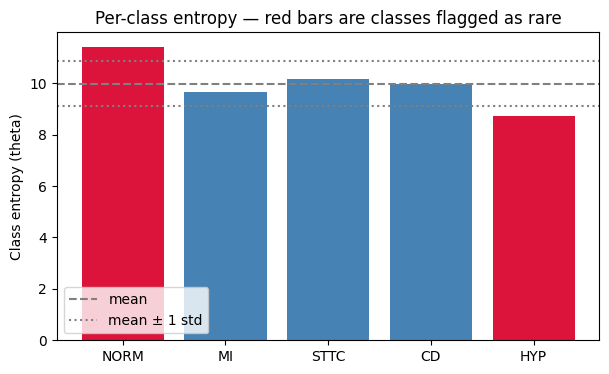

In [ ]:
labels_sorted = sorted(result.class_entropy.keys())
thetas = [result.class_entropy[c] for c in labels_sorted]
colors = ["crimson" if c in result.rare_classes else "steelblue" for c in labels_sorted]

plt.figure(figsize=(7, 4))
plt.bar([idx_to_label[c] for c in labels_sorted], thetas, color=colors)
plt.axhline(result.mean_entropy, color="gray", linestyle="--", label="mean")
plt.axhline(result.mean_entropy + result.std_entropy, color="gray", linestyle=":", label="mean ± 1 std")
plt.axhline(result.mean_entropy - result.std_entropy, color="gray", linestyle=":")
plt.ylabel("Class entropy (theta)")
plt.title("Per-class entropy — red bars are classes flagged as rare")
plt.legend()
plt.show()

## Compare against raw class frequency

Worth checking: is the "rare" class by entropy the same as the class with
fewest raw examples? If not, that's exactly the reference paper's point —
rarity isn't just about count, it's about how spread out/inconsistent the
class's representations are.

In [ ]:
counts = np.bincount(labels, minlength=len(label_to_idx))
for i, c in enumerate(counts):
    print(f"{idx_to_label[i]:6s} n={c:5d}  theta={result.class_entropy.get(i, float('nan')):.4f}")

NORM   n= 2775  theta=11.4070
MI     n=  823  theta=9.6440
STTC   n= 1185  theta=10.1634
CD     n= 1028  theta=9.9600
HYP    n=  431  theta=8.7163


In [ ]:
import pandas as pd, numpy as np, torch
from sklearn.metrics import confusion_matrix
from torch.utils.data import DataLoader

test_ds = PTBXLDataset(split.test_df, cfg.data.ptbxl_dir, label_to_idx)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False, num_workers=2)
preds, ys = [], []
with torch.no_grad():
    for b in test_loader:
        preds.append(model(b["signal"].to(device)).argmax(1).cpu().numpy())
        ys.append(b["label"].numpy())
names = [idx_to_label[i] for i in range(5)]
cm = confusion_matrix(np.concatenate(ys), np.concatenate(preds), labels=range(5), normalize="true")
pd.DataFrame(cm, index=[f"true {n}" for n in names], columns=[f"pred {n}" for n in names]).round(2)

,pred NORM,pred MI,pred STTC,pred CD,pred HYP
true NORM,0.91,0.01,0.06,0.01,0.01
true MI,0.29,0.33,0.21,0.14,0.03
true STTC,0.22,0.06,0.67,0.03,0.03
true CD,0.33,0.08,0.13,0.46,0.01
true HYP,0.34,0.10,0.26,0.03,0.26


In [ ]:
cols = ["age", "sex", "height", "weight"]
print("Missing fraction overall:\n", metadata[cols].isna().mean().round(2))
print("\nMissing fraction, site 1 vs site 2:\n",
      metadata[metadata.site.isin([1, 2])].groupby("site")[cols].apply(lambda d: d.isna().mean()).round(2))
print("\nMean age and sex by class:\n",
      metadata.groupby("superclass")[["age", "sex"]].mean().round(2))
print("\nMean age by site 1 vs 2:\n",
      metadata[metadata.site.isin([1, 2])].groupby("site")["age"].mean().round(1))

Missing fraction overall:
 age       0.00
sex       0.00
height    0.68
weight    0.56
dtype: float64

Missing fraction, site 1 vs site 2:
       age  sex  height  weight
site                          
1     0.0  0.0    0.05    0.08
2     0.0  0.0    0.98    0.98

Mean age and sex by class:
               age   sex
superclass             
CD          71.15  0.40
HYP         66.52  0.43
MI          69.86  0.37
NORM        52.90  0.54
STTC        70.28  0.55

Mean age by site 1 vs 2:
 site
1    69.6
2    70.8
Name: age, dtype: float64


In [4]:

from pathlib import Path

repo = Path("/content/mm-dg-healthcare")

print("=== Python files in src/ ===")
for p in sorted((repo / "src").rglob("*.py")):
    print(p.relative_to(repo))

print("\n=== YAML configuration files ===")
for p in sorted((repo / "configs").glob("*.yaml")):
    print(p.relative_to(repo))

print("\n=== PTB-XL extracted files ===")
data_dir = repo / "data/raw/ptbxl"
if data_dir.exists():
    for p in sorted(data_dir.iterdir())[:20]:
        print(p.name, "(directory)" if p.is_dir() else f"({p.stat().st_size:,} bytes)")
else:
    print("Dataset directory not found:", data_dir)


=== Python files in src/ ===
src/__init__.py
src/data/__init__.py
src/data/domain_split.py
src/data/mimic_cxr_dataset.py
src/data/ptbxl_dataset.py
src/data/ptbxl_multimodal_dataset.py
src/data/ptbxl_text.py
src/evaluation/__init__.py
src/evaluation/metrics.py
src/models/__init__.py
src/models/classifier.py
src/models/fusion.py
src/models/metadata_encoder.py
src/models/signal_encoder.py
src/models/text_encoder.py
src/rare_class/__init__.py
src/rare_class/entropy.py
src/training/__init__.py
src/training/modality_dropout.py
src/training/trainer.py
src/training/trainer_fusion.py
src/utils/__init__.py
src/utils/config.py
src/utils/seed.py

=== YAML configuration files ===
configs/baseline_signal_only.yaml
configs/fusion_full.yaml
configs/fusion_robust.yaml

=== PTB-XL extracted files ===
ptbxl_database.csv (6,594,879 bytes)
records100 (directory)
robots.txt (22 bytes)
scp_statements.csv (9,720 bytes)


In [5]:

import pandas as pd
from pathlib import Path

csv_path = Path("data/raw/ptbxl/ptbxl_database.csv")

if csv_path.exists():
    df = pd.read_csv(csv_path)
    print("Dataset shape:", df.shape)
    print("\nColumns:")
    print(df.columns.tolist())
    print("\nSample metadata:")
    display(df.head(3))
else:
    print("CSV not found. Check the extracted directory listing above.")


Dataset shape: (21799, 28)

Columns:
['ecg_id', 'patient_id', 'age', 'sex', 'height', 'weight', 'nurse', 'site', 'device', 'recording_date', 'report', 'scp_codes', 'heart_axis', 'infarction_stadium1', 'infarction_stadium2', 'validated_by', 'second_opinion', 'initial_autogenerated_report', 'validated_by_human', 'baseline_drift', 'static_noise', 'burst_noise', 'electrodes_problems', 'extra_beats', 'pacemaker', 'strat_fold', 'filename_lr', 'filename_hr']

Sample metadata:


,ecg_id,patient_id,age,sex,height,weight,nurse,site,device,recording_date,...,validated_by_human,baseline_drift,static_noise,burst_noise,electrodes_problems,extra_beats,pacemaker,strat_fold,filename_lr,filename_hr
0,1,15709.0,56.0,1,NaN,63.0,2.0,0.0,CS-12 E,1984-11-09 09:17:34,...,True,NaN,", I-V1,",NaN,NaN,NaN,NaN,3,records100/00000/00001_lr,records500/00000/00001_hr
1,2,13243.0,19.0,0,NaN,70.0,2.0,0.0,CS-12 E,1984-11-14 12:55:37,...,True,NaN,NaN,NaN,NaN,NaN,NaN,2,records100/00000/00002_lr,records500/00000/00002_hr
2,3,20372.0,37.0,1,NaN,69.0,2.0,0.0,CS-12 E,1984-11-15 12:49:10,...,True,NaN,NaN,NaN,NaN,NaN,NaN,5,records100/00000/00003_lr,records500/00000/00003_hr


In [6]:

from pathlib import Path
import pandas as pd

# 1. Inspect report availability and examples
df = pd.read_csv("data/raw/ptbxl/ptbxl_database.csv")

print("=== REPORT COLUMN ===")
if "report" in df.columns:
    reports = df["report"].fillna("").astype(str).str.strip()
    nonempty = reports.ne("")
    print("Total records:", len(df))
    print("Non-empty reports:", int(nonempty.sum()))
    print("Empty reports:", int((~nonempty).sum()))
    print("\nSample non-empty report values:")

    for i, value in enumerate(reports[nonempty].head(5), 1):
        print(f"\nExample {i}:", repr(value[:500]))
else:
    print("No report column found.")

# 2. Inspect existing multimodal files and configs
files = [
    "src/data/ptbxl_multimodal_dataset.py",
    "src/data/ptbxl_text.py",
    "src/models/text_encoder.py",
    "src/models/fusion.py",
    "src/training/trainer_fusion.py",
    "src/training/modality_dropout.py",
    "configs/fusion_full.yaml",
    "configs/fusion_robust.yaml",
]

for filename in files:
    path = Path(filename)
    print(f"\n{'=' * 18} {filename} {'=' * 18}")

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    lines = path.read_text(errors="replace").splitlines()
    for i, line in enumerate(lines[:160], 1):
        print(f"{i:3}: {line}")

    if len(lines) > 160:
        print(f"... {len(lines) - 160} more lines omitted")


=== REPORT COLUMN ===
Total records: 21799
Non-empty reports: 21797
Empty reports: 2

Sample non-empty report values:

Example 1: 'sinusrhythmus periphere niederspannung'

Example 2: 'sinusbradykardie sonst normales ekg'

Example 3: 'sinusrhythmus normales ekg'

Example 4: 'sinusrhythmus normales ekg'

Example 5: 'sinusrhythmus normales ekg'

================== src/data/ptbxl_multimodal_dataset.py ==================
  1: """PTB-XL dataset wrapper for ECG plus non-diagnostic patient metadata."""
  2: from __future__ import annotations
  3: 
  4: import numpy as np
  5: import pandas as pd
  6: import torch
  7: from torch.utils.data import Dataset
  8: 
  9: from src.data.ptbxl_dataset import PTBXLDataset
 10: 
 11: 
 12: class PTBXLMetadataDataset(Dataset):
 13:     """Adds age/sex features normalized using source-training statistics only.
 14: 
 15:     ``metadata_stats`` must be computed from the training split and reused for
 16:     validation/target data. SCP codes, superclass des

In [7]:

%cd /content/mm-dg-healthcare

print("=== Metadata encoder ===")
!sed -n '1,180p' src/models/metadata_encoder.py

print("\n=== Fusion-related tests ===")
!find tests -maxdepth 2 -type f 2>/dev/null

print("\n=== Trainer command options ===")
!python -m src.training.trainer_fusion --help


/content/mm-dg-healthcare
=== Metadata encoder ===
"""Small encoder for non-diagnostic PTB-XL patient metadata.

The primary Phase-3 experiment uses age and sex only. Diagnostic codes and
report-derived fields are intentionally excluded because they reveal the target.
"""
from __future__ import annotations

import torch
import torch.nn as nn


class MetadataEncoder(nn.Module):
    def __init__(self, input_dim: int = 2, embed_dim: int = 128, hidden_dim: int = 32, dropout: float = 0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, embed_dim),
            nn.ReLU(inplace=True),
        )

    def forward(self, metadata: torch.Tensor) -> torch.Tensor:
        if metadata.ndim != 2:
            raise ValueError(f"metadata must have shape (batch, features), got {tuple(metadata.shape)}")
        return self.net(metadata.float())

=

In [8]:

%cd /content/mm-dg-healthcare

print("=== fusion_robust.yaml ===")
!cat configs/fusion_robust.yaml

print("\n=== baseline_signal_only.yaml ===")
!cat configs/baseline_signal_only.yaml

print("\n=== Existing trainer config handling ===")
!sed -n '1,180p' src/utils/config.py


/content/mm-dg-healthcare
=== fusion_robust.yaml ===
# SCAFFOLD — Phase 5 (fusion + modality-dropout robustness training).
# Not yet runnable: src/training/modality_dropout.py is a stub.
# Extends fusion_full.yaml with the dropout schedule that will be read by
# that module once implemented.

seed: 42

data:
  ptbxl_dir: data/raw/ptbxl
  train_sites: [1]
  test_sites: [2]
  use_text_modality: true

model:
  signal_embed_dim: 128
  channel_widths: [32, 64, 128, 128]
  text_encoder_name: "distilbert-base-uncased"
  text_embed_dim: 128
  fusion_strategy: "concat"
  hidden_dim: 64

train:
  batch_size: 32
  epochs: 20
  lr: 0.0005
  weight_decay: 0.00001
  num_workers: 2

modality_dropout:
  enabled: true
  p_drop_signal: 0.15    # probability of zeroing the signal modality per training sample
  p_drop_text: 0.15      # probability of zeroing the text modality per training sample
  # p(both present) = 1 - p_drop_signal - p_drop_text; kept mutually exclusive
  # per-sample so training alway

In [9]:

from pathlib import Path

paths = [
    Path("experiments/results/baseline_signal_only_site1v2/best_model.pt"),
    Path("/content/drive/MyDrive/mm-dg-healthcare-data/results_backup/baseline_signal_only_site1v2/best_model.pt"),
]

for path in paths:
    print(f"{path}: {'FOUND' if path.exists() else 'not found'}")


experiments/results/baseline_signal_only_site1v2/best_model.pt: not found
/content/drive/MyDrive/mm-dg-healthcare-data/results_backup/baseline_signal_only_site1v2/best_model.pt: FOUND


In [10]:

from pathlib import Path
import shutil

source = Path(
    "/content/drive/MyDrive/mm-dg-healthcare-data/"
    "results_backup/baseline_signal_only_site1v2/best_model.pt"
)
destination = Path(
    "/content/mm-dg-healthcare/experiments/results/"
    "baseline_signal_only_site1v2/best_model.pt"
)

assert source.exists(), f"Checkpoint not found: {source}"

destination.parent.mkdir(parents=True, exist_ok=True)
shutil.copy2(source, destination)

print("Restored checkpoint:", destination)
print(f"Size: {destination.stat().st_size / 1024:.1f} KB")


Restored checkpoint: /content/mm-dg-healthcare/experiments/results/baseline_signal_only_site1v2/best_model.pt
Size: 855.5 KB


In [11]:

%cd /content/mm-dg-healthcare

from pathlib import Path
import yaml

baseline_path = Path("configs/baseline_signal_only.yaml")
cfg = yaml.safe_load(baseline_path.read_text())

# Change only the output directory for the new experiment.
cfg["output"]["run_dir"] = (
    "experiments/results/fusion_metadata_site1v2"
)

# Save a separate configuration.
out_path = Path("configs/fusion_metadata.yaml")
out_path.write_text(yaml.safe_dump(cfg, sort_keys=False))

print(out_path.read_text())


/content/mm-dg-healthcare
seed: 42
data:
  ptbxl_dir: data/raw/ptbxl
  train_sites:
  - 1
  test_sites:
  - 2
model:
  embed_dim: 128
  channel_widths:
  - 32
  - 64
  - 128
  - 128
  hidden_dim: 64
train:
  batch_size: 64
  epochs: 20
  lr: 0.001
  weight_decay: 1.0e-05
  num_workers: 2
rare_class:
  k: 5
output:
  run_dir: experiments/results/fusion_metadata_site1v2



In [12]:

from src.utils.config import load_config

cfg = load_config("configs/fusion_metadata.yaml")

print("Dataset:", cfg.data.ptbxl_dir)
print("Training sites:", cfg.data.train_sites)
print("Test sites:", cfg.data.test_sites)
print("Output:", cfg.output.run_dir)
print("Epochs:", cfg.train.epochs)


Dataset: data/raw/ptbxl
Training sites: [1]
Test sites: [2]
Output: experiments/results/fusion_metadata_site1v2
Epochs: 20


In [13]:

from pathlib import Path
import yaml

repo = Path("/content/mm-dg-healthcare")
baseline_cfg = yaml.safe_load(
    (repo / "configs/baseline_signal_only.yaml").read_text()
)

fusion_cfg = {
    "seed": 42,
    "data": {
        "ptbxl_dir": baseline_cfg["data"]["ptbxl_dir"],
        "train_sites": baseline_cfg["data"]["train_sites"],
        "test_sites": baseline_cfg["data"]["test_sites"],
    },
    "model": {
        "signal_embed_dim": 128,
        "channel_widths": [32, 64, 128, 128],
        "metadata_embed_dim": 128,
        "metadata_hidden_dim": 32,
        "fusion_strategy": "concat",
        "hidden_dim": 64,
    },
    "train": {
        "batch_size": 32,
        "epochs": 20,
        "lr": 0.0005,
        "weight_decay": 0.00001,
        "num_workers": 2,
        "validation_fraction": 0.15,
    },
    "modality_dropout": {
        "enabled": False,
        "p_drop_signal": 0.0,
        "p_drop_metadata": 0.0,
    },
    "rare_class": {
        "name": "HYP",
        "k": 5,
    },
    "output": {
        "run_dir": "experiments/results/fusion_metadata_site1v2",
    },
}

config_path = repo / "configs/fusion_metadata.yaml"
config_path.write_text(yaml.safe_dump(fusion_cfg, sort_keys=False))

print(config_path.read_text())


seed: 42
data:
  ptbxl_dir: data/raw/ptbxl
  train_sites:
  - 1
  test_sites:
  - 2
model:
  signal_embed_dim: 128
  channel_widths:
  - 32
  - 64
  - 128
  - 128
  metadata_embed_dim: 128
  metadata_hidden_dim: 32
  fusion_strategy: concat
  hidden_dim: 64
train:
  batch_size: 32
  epochs: 20
  lr: 0.0005
  weight_decay: 1.0e-05
  num_workers: 2
  validation_fraction: 0.15
modality_dropout:
  enabled: false
  p_drop_signal: 0.0
  p_drop_metadata: 0.0
rare_class:
  name: HYP
  k: 5
output:
  run_dir: experiments/results/fusion_metadata_site1v2



In [14]:

%cd /content/mm-dg-healthcare
!python -m pytest tests/ -q


/content/mm-dg-healthcare
................                                                         [100%]
16 passed in 1.44s


In [15]:

from src.utils.config import load_config

cfg = load_config("configs/fusion_metadata.yaml")
print("Fusion config loaded.")
print("Output directory:", cfg.output.run_dir)
print("Modality dropout enabled:", cfg.modality_dropout.enabled)


Fusion config loaded.
Output directory: experiments/results/fusion_metadata_site1v2
Modality dropout enabled: False


In [16]:

%cd /content/mm-dg-healthcare

!grep -nE 'cfg\.|def train|def _predict|metadata_only|modality_dropout' src/training/trainer_fusion.py


/content/mm-dg-healthcare
27:def _predict(model, loader, device, condition="full", mode="fusion"):
32:            if mode == "metadata_only": logits=model(metadata)
34:            elif condition == "metadata_only": logits=model(signal=None, metadata=metadata)
40:def train(cfg):
41:    set_seed(cfg.get("seed",42)); device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
43:    root=Path(cfg.data.ptbxl_dir)
45:    train_sites=list(cfg.data.train_sites); test_sites=list(cfg.data.test_sites)
50:    train_df, val_df = train_test_split(train_domain, test_size=float(cfg.train.get("validation_fraction",0.15)),
51:        random_state=int(cfg.get("seed",42)), stratify=train_domain["superclass"])
58:    nw=int(cfg.train.get("num_workers",2)); bs=int(cfg.train.batch_size)
62:    embed=int(cfg.model.get("signal_embed_dim",128)); widths=tuple(cfg.model.get("channel_widths",[32,64,128,128]))
64:    metadata_encoder=MetadataEncoder(input_dim=2,embed_dim=int(cfg.model.get("metadata_embed_d

In [17]:

from pathlib import Path
import shutil

src = Path("/content/mm-dg-healthcare/configs/fusion_metadata.yaml")
backup_dir = Path("/content/drive/MyDrive/mm-dg-healthcare-data/configs")
backup_dir.mkdir(parents=True, exist_ok=True)

shutil.copy2(src, backup_dir / src.name)
print("Configuration backed up to:", backup_dir / src.name)


Configuration backed up to: /content/drive/MyDrive/mm-dg-healthcare-data/configs/fusion_metadata.yaml


In [20]:

%cd /content/mm-dg-healthcare

!git status --short
!git add configs/fusion_metadata.yaml
!git commit -m "Add ECG and metadata fusion experiment config"


/content/mm-dg-healthcare
A  configs/fusion_metadata.yaml
[main b90efd6] Add ECG and metadata fusion experiment config
 1 file changed, 34 insertions(+)
 create mode 100644 configs/fusion_metadata.yaml


In [19]:

%cd /content/mm-dg-healthcare

!git config --global user.name "Sakina"
!git config --global user.email "skdhilawala1280@gmail.com"

!git config --global --get user.name
!git config --global --get user.email


/content/mm-dg-healthcare
Sakina
skdhilawala1280@gmail.com


In [21]:
%cd /content/mm-dg-healthcare

!git log -1 --oneline
!git status --short

import torch
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

/content/mm-dg-healthcare
b90efd6 (HEAD -> main) Add ECG and metadata fusion experiment config
GPU available: True
GPU: Tesla T4


In [22]:
%cd /content/mm-dg-healthcare
!git status --short

/content/mm-dg-healthcare


In [23]:
!git add 03_rare_class_identification.ipynb
!git commit -m "Complete rare class identification analysis"

fatal: pathspec '03_rare_class_identification.ipynb' did not match any files
On branch main
Your branch is ahead of 'origin/main' by 1 commit.
  (use "git push" to publish your local commits)

nothing to commit, working tree clean


In [24]:
%cd /content/mm-dg-healthcare

!find . -name "*.ipynb"
!git status --short

/content/mm-dg-healthcare
./notebooks/02_baseline_signal_only.ipynb
./notebooks/00_colab_setup.ipynb
./notebooks/06_ablation_results.ipynb
./notebooks/05_missing_modality_robustness.ipynb
./notebooks/04_multimodal_fusion.ipynb
./notebooks/03_rare_class_identification.ipynb
./notebooks/01_data_exploration_ptbxl.ipynb


In [25]:
%cd /content/mm-dg-healthcare
!git push origin main

/content/mm-dg-healthcare
fatal: could not read Username for 'https://github.com': No such device or address


In [26]:
from google.colab import files
files.download(
    "/content/mm-dg-healthcare/configs/fusion_metadata.yaml"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Next steps (not yet built)

This notebook establishes *which class is rare* and confirms the entropy
math (already unit-tested in `tests/test_entropy.py`) runs correctly on
real learned embeddings. Phases 3–6 (multimodal fusion, missing-modality
robustness, full ablation) are scaffolded in `src/models/fusion.py`,
`src/models/text_encoder.py`, and `src/training/modality_dropout.py` —
see each file's docstring for the implementation plan, and
`notebooks/04_multimodal_fusion.ipynb` onward for their placeholders.